# UC2 — Caderno de Estudos: Aulas 1 a 6

**Criar e Manipular Dados Utilizando Matemática Estatística** · Analista de Dados · SENAC RJ
Prof. Cassio Ribeiro

Este caderno reúne, em um só lugar, tudo o que foi visto nas Aulas 1 a 6: ambiente e DataFrame, exploração e quartis, média e mediana, outliers, visualização com Matplotlib, variância, desvio padrão, covariância e correlação.

**Como usar**

- As células de **código com exemplos prontos** devem ser executadas e lidas com atenção. Altere valores e rode de novo para ver o que muda.
- As **Atividades** têm o enunciado em linguagem de negócio e uma célula de código **em branco**: o código é seu. Use o que foi visto nas aulas.
- Execute as células **na ordem**, de cima para baixo: os exemplos criam variáveis que as seções seguintes usam.

**Bases usadas**

| Base | Arquivo / origem | Uso |
|---|---|---|
| Vendas do NaraStore | `vendas_narastore.xlsx` (mesma pasta deste caderno) | Aula 1, 3 e 5 |
| Ocorrências do ISP-RJ | link do Instituto de Segurança Pública do RJ | Aulas 2 a 6 |

**Sumário**

1. Preparando o ambiente
2. Aula 1 — Ambiente virtual, Jupyter e DataFrame
3. Aula 2 — Explorando dados: groupby e quartis
4. Aula 3 — Média, mediana e a distância entre elas
5. Aula 4 — Outliers e IQR
6. Aula 5 — Visualização com Matplotlib e subplots
7. Aula 6 — Variância, desvio padrão, covariância e correlação

## 0. Preparando o ambiente

Cada projeto deve ter o seu **ambiente virtual (VEnv)**, isolado das demais instalações do computador. No CMD do Windows, dentro da pasta do projeto:

```
python -m venv venv
venv\Scripts\activate
pip install pandas numpy matplotlib openpyxl ipykernel
```

Para sair do ambiente: `deactivate`. Para registrar as bibliotecas do projeto e recriá-las em outra máquina:

```
pip freeze > requirements.txt
pip install -r requirements.txt
```

No VS Code, ao abrir este arquivo `.ipynb`, escolha o **kernel** do seu VEnv (canto superior direito do caderno).

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

print('Matplotlib', matplotlib.__version__)

Matplotlib 3.11.2


Este caderno usa **Matplotlib 3.10 ou superior** (por causa do parâmetro `orientation` do boxplot, visto na Aula 5). Se a versão for menor, atualize com `pip install -U matplotlib`.

---
# Aula 1 — Ambiente virtual, Jupyter e DataFrame

## 1.1 Variáveis qualitativas e quantitativas

Antes de analisar dados, precisamos saber que **tipo de informação** cada coluna guarda.

| Tipo | O que descreve | Exemplos |
|---|---|---|
| **Qualitativa** | uma categoria, um rótulo | nome do produto, cidade, cor |
| **Quantitativa** | uma quantidade, um número que pode ser medido e calculado | vendas, idade, preço |

Regra prática: se faz sentido **somar ou tirar a média**, a variável é quantitativa. Se só faz sentido **agrupar e contar**, é qualitativa.

## 1.2 O Jupyter Notebook

Um caderno é formado por **células**. Existem dois tipos que usamos aqui:

- **Código**: executa Python;
- **Markdown**: texto explicativo (como esta célula).

Atalhos para executar uma célula de código: `Shift + Enter` executa e avança para a próxima; `Ctrl + Enter` executa e permanece na mesma.

Para mostrar resultados, há duas formas. O `print()` escreve texto simples; o `display()` mostra o objeto de forma formatada, como uma tabela quando for um DataFrame.

## 1.3 Dicionário: a base de um DataFrame manual

Para criar um DataFrame à mão, sem dados externos, o **dicionário** é a melhor estrutura: as **chaves** viram os nomes das colunas e os **valores** (listas) viram os dados de cada coluna.

In [ ]:
dados_exemplo = {
    'vendedor': ['Ana', 'Carlos', 'Beatriz'],
    'total':    [1500, 2300, 1800]
}

df_exemplo = pd.DataFrame(dados_exemplo)

print(df_exemplo)
display(df_exemplo)

Compare as duas saídas: o `print()` mostra texto; o `display()` mostra uma tabela formatada. Um DataFrame funciona como uma planilha do Excel: tem linhas e colunas, cada linha com um número de índice.

## 1.4 Lendo uma planilha do Excel

Na prática, os dados vêm de arquivos. Para ler `.xlsx` com o Pandas usamos `pd.read_excel()`; ele depende do pacote **openpyxl** (`pip install openpyxl`).

O arquivo `vendas_narastore.xlsx` tem **duas tabelas na mesma aba**: as vendas (colunas A a G) e as metas por vendedor (colunas J e K). Com o parâmetro `usecols` lemos apenas o intervalo que nos interessa.

In [ ]:
df = pd.read_excel('vendas_narastore.xlsx', usecols='A:G')

display(df)

## 1.5 Operações básicas com uma coluna

Cada coluna é uma **Série** e aceita métodos como `sum()` (soma), `mean()` (média), `max()` (maior valor) e `min()` (menor valor).

In [ ]:
total = df['Total (R$)'].sum()
media_venda = df['Total (R$)'].mean()
maior_venda = df['Total (R$)'].max()
menor_venda = df['Total (R$)'].min()

print(f'Total vendido: R$ {total:.2f}')
print(f'Média por venda: R$ {media_venda:.2f}')
print(f'Maior venda: R$ {maior_venda:.2f}')
print(f'Menor venda: R$ {menor_venda:.2f}')

### Atividade 1.1 — Classificando as variáveis

Para cada coluna da base do NaraStore, indique se a variável é **qualitativa** ou **quantitativa**. Escreva a sua resposta nesta célula, editando a tabela.

| Coluna | Tipo |
|---|---|
| Data | |
| Vendedor | |
| Produto | |
| Categoria | |
| Quantidade | |
| Valor Unit. (R$) | |
| Total (R$) | |

### Atividade 1.2 — Resumo de vendas do NaraStore

Você acaba de entrar como estagiário(a) na equipe comercial do NaraStore. O analista sênior deixou o relatório de vendas de março/2025 e pediu que você prepare o ambiente, carregue os dados e responda:

1. Qual foi o total vendido no período?
2. Qual foi o valor médio por venda?
3. Qual foi a maior venda individual e qual foi a menor?

Documente cada passo com células de texto.

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

---
# Aula 2 — Explorando dados: groupby e quartis

Agora vamos trabalhar com uma base real: as **ocorrências registradas pelas delegacias do estado do Rio de Janeiro**, divulgadas pelo ISP-RJ (Instituto de Segurança Pública). Cada linha traz os números de um mês em uma **CISP** (circunscrição de delegacia).

## 2.1 Carregando a base do ISP-RJ

O Pandas lê o arquivo direto do link. Dois parâmetros são necessários:

- `encoding='latin-1'`: a codificação de caracteres do arquivo (acentos);
- `sep=';'`: o separador de colunas, que neste arquivo é o ponto e vírgula.

In [ ]:
url = 'https://www.ispdados.rj.gov.br/Arquivos/BaseDPEvolucaoMensalCisp.csv'

isp = pd.read_csv(url, encoding='latin-1', sep=';')

## 2.2 Explorando o DataFrame

In [ ]:
print(isp.shape)

`shape` devolve (linhas, colunas). Para ver as primeiras linhas das colunas que vamos usar:

In [ ]:
isp[['cisp', 'ano', 'mes', 'regiao', 'munic', 'furto_celular', 'roubo_veiculo']].head()

`info()` mostra o tipo de cada coluna e quantos valores existem; `describe()` resume as colunas numéricas (contagem, média, desvio, mínimo, quartis e máximo).

In [ ]:
isp[['cisp', 'ano', 'regiao', 'munic', 'furto_celular', 'roubo_veiculo']].info()

In [ ]:
isp[['furto_celular', 'roubo_veiculo']].describe()

## 2.3 Variáveis desta base

- **Qualitativas:** `cisp` (código da delegacia), `regiao`, `munic` (município);
- **Quantitativas:** os contadores de ocorrências, como `furto_celular`, `roubo_veiculo`, `furto_veiculos` e `recuperacao_veiculos`;
- **Tempo:** `ano`, `mes` e `mes_ano`.

## 2.4 Selecionando linhas e colunas: loc e query

- `loc[linhas, colunas]` seleciona por **rótulo** (nomes de colunas, índices);
- `query()` filtra linhas com uma condição escrita como texto.

In [ ]:
isp.loc[0:4, ['cisp', 'munic', 'furto_celular']]

In [ ]:
capital = isp.query("regiao == 'Capital' and ano == 2024")

capital[['cisp', 'mes', 'furto_celular']].head()

Neste filtro usamos `and` para combinar duas condições: região **e** ano.

## 2.5 Agrupando: groupby, sum, reset_index e sort_values

Os dados são mensais por CISP. Para saber **quanto cada CISP registrou em 2024**, agrupamos por CISP e somamos:

- `groupby('cisp')` separa as linhas por CISP;
- `['furto_celular'].sum()` soma a coluna em cada grupo;
- `reset_index()` transforma o resultado de volta em um DataFrame comum;
- `sort_values(by=..., ascending=False)` ordena do maior para o menor.

In [ ]:
por_cisp = capital.groupby('cisp')['furto_celular'].sum().reset_index()
por_cisp = por_cisp.sort_values(by='furto_celular', ascending=False)

display(por_cisp.head(10))

## 2.6 Do DataFrame para o array: média e mediana com NumPy

Para os cálculos estatísticos, transformamos a coluna em um **array** do NumPy.

In [ ]:
dados = np.array(por_cisp['furto_celular'])

media = np.mean(dados)
mediana = np.median(dados)

print('Quantidade de CISPs:', len(dados))
print('Média:', media)
print('Mediana:', mediana)

## 2.7 Quartis: Q1, Q2 e Q3

Os **quartis** dividem os dados ordenados em quatro partes iguais:

- **Q1** (25%): 25% dos valores estão abaixo dele;
- **Q2** (50%): é a **mediana**, o valor do meio;
- **Q3** (75%): 75% dos valores estão abaixo dele.

Calculamos cada um com `np.percentile()`, em variáveis separadas.

In [ ]:
q1 = np.percentile(dados, 25)
q2 = np.percentile(dados, 50)
q3 = np.percentile(dados, 75)

print('Q1:', q1)
print('Q2 (mediana):', q2)
print('Q3:', q3)

## 2.8 Usando o quartil para filtrar: os 25% maiores

Os valores acima do Q3 formam o grupo dos **25% de CISPs com mais ocorrências**. Para filtrar, escrevemos a condição entre colchetes.

In [ ]:
top25 = por_cisp[por_cisp['furto_celular'] > q3]

display(top25)

### Atividade 2.1 — Roubo de veículos na Baixada Fluminense

A gerência de uma seguradora quer entender onde o roubo de veículos se concentra na **Baixada Fluminense** em **2024** (variável `roubo_veiculo`).

1. Monte o ranking dos municípios, do que mais registrou ao que menos registrou.
2. Calcule Q1, Q2 e Q3 do total por município.
3. Quais municípios formam o grupo dos 25% com mais roubos de veículos?

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

### Atividade 2.2 — Furto de veículos na Baixada Fluminense

Repita a análise para a variável `furto_veiculos`, ainda na Baixada Fluminense em 2024, agora comparando as **CISPs** em vez dos municípios. Existe diferença entre as CISPs que lideram os furtos e as que lideram os roubos de veículos?

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

---
# Aula 3 — Média, mediana e a distância entre elas

## 3.1 Medidas de tendência central

As medidas de tendência central resumem um conjunto de dados em **um valor que representa o centro**:

- **Média:** soma de todos os valores dividida pela quantidade. É sensível a valores extremos;
- **Mediana:** valor do meio quando os dados estão ordenados (igual ao Q2). Quase não é afetada por extremos.

Retomando o array da Capital em 2024 (furtos de celular por CISP):

In [ ]:
dados = np.array(por_cisp['furto_celular'])

media = np.mean(dados)
mediana = np.median(dados)

print(f'Média: {media:.1f}')
print(f'Mediana: {mediana:.1f}')

A média é bem maior do que a mediana. Será que a média é uma boa representante desses dados? Para responder, vamos medir **a distância entre as duas**.

## 3.2 A distância entre média e mediana

$$\text{distância} = \frac{\text{média} - \text{mediana}}{\text{mediana}}$$

O resultado, em porcentagem, indica se a média é confiável:

| Distância (valor absoluto) | Leitura |
|---|---|
| até 10% | a média tende a ser uma medida **confiável** |
| de 10% até 25% | os valores extremos influenciam a média **moderadamente**; pode ser que ela seja confiável, ou não |
| 25% ou mais | os extremos influenciam **muito** a média; ela tende a **não** ser confiável |

**Direção da influência:** se a média é **maior** que a mediana, os valores **maiores** estão puxando a média; se é **menor**, são os valores **menores**.

In [ ]:
distancia = (media - mediana) / mediana

print(f'Distância: {distancia:.1%}')

In [ ]:
if abs(distancia) <= 0.10:
    leitura = 'média confiável'
elif abs(distancia) < 0.25:
    leitura = 'influência moderada dos extremos'
else:
    leitura = 'média não confiável'

if media > mediana:
    direcao = 'os valores maiores puxam a média'
else:
    direcao = 'os valores menores puxam a média'

print(leitura)
print(direcao)

Nos furtos de celular por CISP na Capital, a distância passa de 25%: a média **não** representa bem o conjunto, porque as CISPs com muitos registros a puxam para cima. Nesse caso, a **mediana** é a melhor medida de tendência central.

## 3.3 Coluna derivada

Podemos criar uma coluna nova a partir de outras. No NaraStore, vamos recalcular o total de cada venda como **quantidade × valor unitário**:

In [ ]:
df['Total calculado (R$)'] = df['Quantidade'] * df['Valor Unit. (R$)']

df[['Produto', 'Quantidade', 'Valor Unit. (R$)', 'Total calculado (R$)']].head()

### Atividade 3.1 — O ticket médio do NaraStore

Em uma reunião, o gerente comercial afirmou: "a média de valor das nossas vendas representa bem o que o NaraStore vende". Verifique a afirmação com os dados da coluna `Total (R$)`. A média é uma boa medida de tendência central? Apresente os cálculos e uma conclusão objetiva.

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

### Atividade 3.2 — Roubo de celular na Capital

A secretaria quer usar um único número para resumir o roubo de celular por CISP na **Capital** em **2024** (variável `roubo_celular`). Calcule o total por CISP, a média e a mediana, e a distância entre elas. Qual medida deve ser usada como resumo? Os valores maiores ou os menores puxam a média?

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

### Atividade 3.3 — Roubo de veículos por município na Baixada

Repita a verificação para o total de `roubo_veiculo` por **município** da Baixada Fluminense em 2024. Compare a distância encontrada com a do exercício anterior e explique o que muda na confiabilidade da média.

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

---
# Aula 4 — Outliers e IQR

**Outliers** são valores muito acima ou muito abaixo dos demais. Em dados de negócio costumam responder perguntas como: quais produtos venderam muito mais (ou muito menos) que os outros? Quais delegacias registraram bem mais ocorrências que as demais?

## 4.1 O intervalo interquartil (IQR)

O **IQR** é a distância entre Q3 e Q1 e representa os 50% centrais dos dados.

$$\text{IQR} = Q3 - Q1$$

Os **limites** que separam os valores normais dos outliers são:

$$\text{limite superior} = Q3 + 1{,}5 \times \text{IQR} \qquad \text{limite inferior} = Q1 - 1{,}5 \times \text{IQR}$$

Valores **acima do limite superior** são outliers superiores; valores **abaixo do limite inferior** são outliers inferiores.

In [ ]:
q1 = np.percentile(dados, 25)
q3 = np.percentile(dados, 75)

iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
limite_inferior = q1 - 1.5 * iqr

print('IQR:', iqr)
print('Limite superior:', limite_superior)
print('Limite inferior:', limite_inferior)

## 4.2 Encontrando os outliers

Usamos filtros no DataFrame `por_cisp` (furtos de celular por CISP na Capital, 2024) e ordenamos com `sort_values()`.

In [ ]:
outliers_superiores = por_cisp[por_cisp['furto_celular'] > limite_superior]
outliers_superiores = outliers_superiores.sort_values(by='furto_celular', ascending=False)

display(outliers_superiores)

In [ ]:
outliers_inferiores = por_cisp[por_cisp['furto_celular'] < limite_inferior]
outliers_inferiores = outliers_inferiores.sort_values(by='furto_celular')

display(outliers_inferiores)

Há **outliers superiores**: algumas CISPs registraram muito mais furtos que a maioria. Não há outliers inferiores porque o limite inferior é **negativo** e não existe contagem negativa de ocorrências.

### Atividade 4.1 — Furto de veículos na Capital

A diretoria de uma seguradora quer saber se alguma CISP da **Capital** foge muito do padrão de **furto de veículos** (variável `furto_veiculos`) em **2024**.

1. Calcule o total por CISP.
2. Calcule o IQR e os limites.
3. Liste os outliers superiores e inferiores, do maior para o menor.
4. Quais CISPs merecem atenção especial da seguradora?

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

### Atividade 4.2 — Roubo de veículos por município na Baixada

Aplique o mesmo critério ao total de `roubo_veiculo` por **município** da Baixada Fluminense em 2024. Algum município é um outlier? Compare o resultado com o que você já encontrou sobre a confiabilidade da média nessa variável.

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

---
# Aula 5 — Visualização com Matplotlib e subplots

Até aqui calculamos tudo em números. Agora vamos **desenhar**. Todo gráfico precisa de duas informações: o que está sendo comparado (categorias ou tempo) e o valor medido. Em Python, isso vira **dois arrays**: um para o eixo x e outro para o eixo y.

Já temos o `import matplotlib.pyplot as plt` no início do caderno. No Jupyter o gráfico aparece logo abaixo da célula; em scripts `.py` usamos `plt.show()`.

## 5.1 Preparando os dados do NaraStore

Faturamento por vendedor, com os nomes e os valores em arrays:

In [ ]:
vendas_vendedor = df.groupby('Vendedor')['Total (R$)'].sum().reset_index()
vendas_vendedor = vendas_vendedor.sort_values(by='Total (R$)', ascending=False)

vendedores = np.array(vendas_vendedor['Vendedor'])
totais = np.array(vendas_vendedor['Total (R$)'])

display(vendas_vendedor)

## 5.2 `plt.bar()`: barras verticais

A forma mais simples: o primeiro argumento são as **categorias** (eixo x) e o segundo os **valores** (eixo y). Não precisamos criar figura nem eixos.

In [ ]:
plt.bar(vendedores, totais)

## 5.3 `plt.title()`: dizendo o que o gráfico mostra

Um bom título responde **o quê, onde e quando**. Com um título descritivo, rótulos nos eixos ficam redundantes.

In [ ]:
plt.bar(vendedores, totais)
plt.title('Faturamento por vendedor - mar/2025')

## 5.4 `plt.barh()`: barras horizontais

Mesma ideia, com as barras deitadas. É ótimo quando os nomes das categorias são longos. O `barh` desenha de baixo para cima; por isso ordenamos do **menor para o maior**, e o maior fica no topo.

In [ ]:
vendas_produto = df.groupby('Produto')['Total (R$)'].sum().reset_index()
vendas_produto = vendas_produto.sort_values(by='Total (R$)')

produtos = np.array(vendas_produto['Produto'])
total_produto = np.array(vendas_produto['Total (R$)'])

plt.barh(produtos, total_produto)
plt.title('Faturamento por produto - mar/2025')

## 5.5 Ajustes: tamanho, rotação e margens

- `plt.figure(figsize=(largura, altura))` define o tamanho da figura, em polegadas;
- `plt.xticks(rotation=45)` gira os nomes do eixo x para não se sobreporem;
- `plt.tight_layout()` ajusta as margens para nada ficar cortado.

Compare os dois gráficos abaixo: sem ajustes, os nomes se sobrepõem.

In [ ]:
plt.bar(produtos, total_produto)
plt.title('Faturamento por produto - mar/2025')

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(produtos, total_produto)
plt.xticks(rotation=45)
plt.title('Faturamento por produto - mar/2025')
plt.tight_layout()

## 5.6 Exemplo: faturamento por categoria

Agrupar, ordenar, guardar em arrays, plotar e dar um título.

In [ ]:
vendas_categoria = df.groupby('Categoria')['Total (R$)'].sum().reset_index()
vendas_categoria = vendas_categoria.sort_values(by='Total (R$)', ascending=False)

categorias = np.array(vendas_categoria['Categoria'])
total_categoria = np.array(vendas_categoria['Total (R$)'])

plt.bar(categorias, total_categoria)
plt.title('Faturamento por categoria - mar/2025')

## 5.7 Dados temporais com `plt.plot()`

Para dados no tempo, usamos a **linha**. Ela liga pontos consecutivos e por isso só faz sentido quando existe uma ordem, como o tempo. Vamos ver os furtos de celular no estado do RJ por ano.

O ano mais recente da base ainda está em andamento; por isso o recorte de 2015 a 2025 compara apenas anos completos.

In [ ]:
por_ano = isp.groupby('ano')['furto_celular'].sum().reset_index()
por_ano = por_ano.query('ano >= 2015 and ano <= 2025')

anos = np.array(por_ano['ano'])
furtos = np.array(por_ano['furto_celular'])

plt.plot(anos, furtos)
plt.xticks(anos)
plt.title('Furtos de celular no RJ por ano')

## 5.8 Linha ou barra?

Observe o mesmo faturamento por vendedor desenhado com linha: ela sugere uma continuidade entre vendedores que não existe.

**Regra:** `plt.plot()` para dados **temporais**; `plt.bar()` e `plt.barh()` para dados **categóricos**.

In [ ]:
plt.plot(vendedores, totais)
plt.title('Faturamento por vendedor - mar/2025')

## 5.9 Menor valor, maior valor e amplitude total

Para o boxplot vamos retomar o array da Capital em 2024. Os extremos mostram a **amplitude total**: a distância entre o maior e o menor valor.

In [ ]:
menor = dados.min()
maior = dados.max()
amplitude = maior - menor

print(menor, maior, amplitude)

## 5.10 Anatomia do boxplot

O boxplot resume a distribuição em uma única imagem:

| Elemento | O que representa |
|---|---|
| Caixa | de **Q1** a **Q3** (os 50% centrais) |
| Linha dentro da caixa | **mediana** (Q2) |
| Triângulo (com `showmeans=True`) | **média** |
| Bigodes | até o valor real mais extremo **dentro** dos limites do IQR (não até o limite teórico) |
| Círculos | **outliers** |

Se a média está à direita da mediana, os valores altos estão puxando a média para cima, o mesmo que a distância da Aula 3 indicava.

In [ ]:
plt.boxplot(dados, orientation='horizontal', showmeans=True)
plt.title('Furtos de celular por CISP - Capital 2024')

`orientation='horizontal'` deixa o boxplot deitado. Em versões do Matplotlib anteriores à 3.10, usava-se `vert=False`.

### Atividade 5.1 — Roubo de veículos na Baixada: três gráficos

Você é analista de dados de uma seguradora de veículos. Antes de revisar o preço das apólices na Baixada Fluminense, a diretoria pediu uma análise do **roubo de veículos** na região, usando a base do ISP-RJ (variável `roubo_veiculo`).

1. Quais municípios da Baixada concentraram mais roubos de veículos em 2024? A diretoria quer ver o ranking completo.
2. Como evoluiu o total de roubos de veículos na Baixada entre 2015 e 2025?
3. Considerando as CISPs da Baixada em 2024, os valores são parecidos entre si ou existem CISPs muito fora do padrão? A média representa bem esse conjunto?

Entregue cada resposta com um gráfico de título claro e uma conclusão de uma frase.

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

## 5.11 Vários gráficos, uma só figura: `plt.subplots()`

Até aqui cada gráfico ocupou uma figura própria. Um **painel** reúne vários gráficos na mesma figura, organizados em linhas e colunas. Vantagens: comparação lado a lado, uma única imagem para relatórios e padronização do tamanho.

```python
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
```

- `fig` é a figura inteira, como uma folha de papel;
- `axes` é um array com os gráficos que ficam sobre a folha;
- os dois primeiros números são **linhas e colunas**: `(1, 2)` = 1 linha e 2 colunas;
- com uma linha só, usamos um índice: `axes[0]` é o gráfico da esquerda e `axes[1]` o da direita.

Em vez de `plt.bar()` usamos `axes[0].bar()`; em vez de `plt.title()`, `axes[0].set_title()`.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(categorias, total_categoria)
axes[0].set_title('Faturamento por categoria')
axes[1].barh(produtos, total_produto)
axes[1].set_title('Faturamento por produto')
plt.tight_layout()

## 5.12 `plt.text()`: escrevendo dentro do gráfico

`plt.text(x, y, texto)` escreve o texto na posição (x, y) do gráfico. Em gráfico de barras, o x é a **posição da barra** (0 é a primeira) e o y é o valor. `ha='center'` centraliza o texto no ponto x e `color` muda a cor. Com **f-string**, o texto pode trazer valores calculados: `{valor:.2f}`.

In [ ]:
plt.bar(vendedores, totais)
plt.text(0, 3500, f'R$ {totais[0]:.2f}', ha='center', color='white')
plt.title('Faturamento por vendedor - mar/2025')

## 5.13 Calculando as medidas para o painel

Vamos montar um texto com as medidas da distribuição de furtos de celular por CISP na Capital, para escrever dentro do painel.

In [ ]:
menor = dados.min()
maior = dados.max()
amplitude = maior - menor
q1 = np.percentile(dados, 25)
q2 = np.percentile(dados, 50)
q3 = np.percentile(dados, 75)
media = np.mean(dados)
mediana = np.median(dados)
distancia = (media - mediana) / mediana

texto = (f"Menor valor: {menor:.0f}\n"
         f"Q1: {q1:.1f}\n"
         f"Mediana (Q2): {q2:.1f}\n"
         f"Q3: {q3:.1f}\n"
         f"Maior valor: {maior:.0f}\n"
         f"Amplitude total: {amplitude:.0f}\n"
         f"Média: {media:.1f}\n"
         f"Distância média-mediana: {distancia:.1%}")

print(texto)

## 5.14 Painel 1×2: boxplot e medidas

`axes[1].axis('off')` esconde bordas e números do eixo, deixando só o texto; `axes[1].text(x, y, texto)` segue a regra do `plt.text()`; `va='top'` alinha o texto pelo topo.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot(dados, orientation='horizontal', showmeans=True)
axes[0].set_title('Furtos por CISP - Capital 2024')
axes[1].axis('off')
axes[1].text(0.05, 0.95, texto, va='top', fontsize=12)
axes[1].set_title('Medidas calculadas')
plt.tight_layout()

## 5.15 Painel 2×2: linhas e colunas

Com duas dimensões, o índice tem **linha e coluna**: `axes[linha, coluna]`. A contagem começa em zero: `axes[0, 0]` é o gráfico do canto superior esquerdo e `axes[1, 1]` o do canto inferior direito.

```python
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
```

Exemplo completo: quatro informações sobre os furtos de celular em uma única figura.

In [ ]:
top_cisp = por_cisp.sort_values(by='furto_celular', ascending=False).head(8)
top_cisp = top_cisp.sort_values(by='furto_celular')
nomes_cisp = np.array('CISP ' + top_cisp['cisp'].astype(str))
valores_cisp = np.array(top_cisp['furto_celular'])

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes[0, 0].plot(anos, furtos)
axes[0, 0].set_title('Furtos de celular no RJ por ano')
axes[0, 1].barh(nomes_cisp, valores_cisp)
axes[0, 1].set_title('Top 8 CISPs - Capital 2024')
axes[1, 0].boxplot(dados, orientation='horizontal', showmeans=True)
axes[1, 0].set_title('Furtos por CISP - Capital 2024')
axes[1, 1].axis('off')
axes[1, 1].text(0.05, 0.95, texto, va='top', fontsize=12)
axes[1, 1].set_title('Medidas calculadas')
plt.tight_layout()

### Atividade 5.2 — Painel executivo: roubo de celular na Capital

Você faz parte de uma consultoria contratada pela Secretaria de Segurança. Para a reunião de amanhã, o secretário quer **uma única imagem** com o panorama do roubo de celular na Capital do Rio de Janeiro, usando a base do ISP-RJ (variável `roubo_celular`).

- Como o roubo de celular na Capital evoluiu entre 2015 e 2025?
- Quais são as 8 CISPs com mais roubos de celular em 2024?
- Em 2024, a distribuição entre as CISPs é equilibrada? Existem CISPs fora do padrão?
- Um quadro com as medidas que sustentam a conclusão: menor e maior valor, amplitude, quartis, média e a distância entre média e mediana.

Reúna as quatro informações em uma só figura, com título claro em cada parte, e escreva uma conclusão de duas frases para o secretário.

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

---
# Aula 6 — Variância, desvio padrão, covariância e correlação

*Aprendendo com NumPy e Pandas — do jeito fácil!*

## O que já sabemos

| Conceito | Ideia |
|---|---|
| Mediana | O valor do meio: divide os dados em dois grupos iguais. |
| Q1, Q3 e IQR | Quartis que mostram como os dados se distribuem em 4 partes. |
| Média vs mediana | Compara o centro dos dados e revela se há valores extremos. |
| Outliers | Valores que fogem do padrão e podem distorcer a análise. |

## O que vamos aprender hoje

Quatro conceitos novos, todos conectados:

1. **Variância:** mede o quanto os dados se afastam da média. Quanto maior, mais espalhados.
2. **Desvio padrão:** a "raiz" da variância, mais fácil de interpretar e na mesma unidade dos dados.
3. **Covariância:** verifica se duas variáveis "andam juntas", se sobem ou descem ao mesmo tempo.
4. **Correlação:** mede a **força** da relação entre duas variáveis, em uma escala de −1 a +1.

> **Atenção:** todas essas medidas usam **apenas variáveis quantitativas** (números que representam quantidades, como nota, horas ou número de ocorrências). Nomes, categorias e códigos identificadores não entram nas contas.

## 6.1 Nosso conjunto de dados

Notas e horas de estudo de 8 alunos fictícios. Vamos criar o DataFrame a partir de um dicionário, como na Aula 1.

In [7]:

dados_alunos = {
    'aluno': ['Ana', 'Bruno', 'Carol', 'Diego', 'Elisa', 'Felipe', 'Gabi', 'Hugo'],
    'nota':  [8.5, 6.0, 9.2, 5.5, 7.8, 4.0, 9.0, 6.5],
    'horas': [6, 3, 8, 2, 5, 1, 7, 4]
}

df_alunos = pd.DataFrame(dados_alunos)
display(df_alunos)

,aluno,nota,horas
0,Ana,8.5,6
1,Bruno,6.0,3
2,Carol,9.2,8
3,Diego,5.5,2
4,Elisa,7.8,5
5,Felipe,4.0,1
6,Gabi,9.0,7
7,Hugo,6.5,4


**Perceba:**

- Alunos com mais horas de estudo tendem a ter notas mais altas.
- Felipe estudou pouco (1h) e teve a menor nota.
- Carol estudou bastante (8h) e teve a maior nota.
- Esse padrão será confirmado pela covariância e pela correlação.

## 6.2 Variância — passo a passo

**Ideia central:** a variância responde à pergunta *"os dados estão concentrados ou espalhados em torno da média?"*

| Passo | O que fazer | Exemplo |
|---|---|---|
| 1 — Calcule a média | Some todos os valores e divida pela quantidade. | (4 + 6 + 8) ÷ 3 = 6 |
| 2 — Calcule a distância² | Subtraia a média de cada valor e eleve ao quadrado. | (4−6)² = 4 · (6−6)² = 0 · (8−6)² = 4 |
| 3 — Tire a média das distâncias² | Some os quadrados e divida pela quantidade. | (4 + 0 + 4) ÷ 3 = 2,67 |

> **Por que elevar ao quadrado?** Para evitar que distâncias negativas e positivas se cancelem e resultem em zero!

### Variância no Python

`np.var()` com o nosso dataset de alunos:

In [8]:
variancia = np.var(df_alunos['nota'])
print(f"Variância: {variancia:.2f}")

Variância: 3.02


**O que significa 3,02?** Em média, cada nota está afastada 3,02 pontos² da média geral. Como a unidade fica em "pontos ao quadrado", usamos o **desvio padrão** para interpretar melhor.

## 6.3 Desvio padrão — a mais usada!

É a **raiz quadrada da variância**.

**Por que usar desvio padrão e não variância?** A variância eleva ao quadrado, então a unidade fica "nota²", que é difícil de interpretar. O desvio padrão tira a raiz quadrada e volta à unidade original: "nota". Assim fica muito mais fácil dizer: *"as notas variam em média ±1,74 pontos"*.

**Fórmula:** σ = √variância → √3,02 ≈ 1,74

| Desvio padrão | Leitura |
|---|---|
| σ ≈ 0 | Baixíssimo: todos os valores são quase iguais. Muito consistente. |
| σ médio | Moderado: existe alguma variação, mas não é extrema. |
| σ alto | Elevado: dados muito espalhados. Alta variação. |

### Desvio padrão no Python

`np.std()` e a **faixa típica**, que vai de `média - desvio` até `média + desvio`:

In [9]:
desvio = np.std(df_alunos['nota'])
print(f"Desvio Padrão: {desvio:.2f}")

media = np.mean(df_alunos['nota'])
print(f"Média das notas: {media:.2f}")
print(f"Faixa típica: {media - desvio:.2f} até {media + desvio:.2f}")

Desvio Padrão: 1.74
Média das notas: 7.06
Faixa típica: 5.32 até 8.80


**O que isso significa?**

- A maioria dos alunos tem notas entre 5,32 e 8,80.
- Abaixo de 5,32: desempenho abaixo do esperado.
- Acima de 8,80: aluno se destaca.

### A faixa típica no gráfico

Para **ver** a faixa típica, desenhamos as notas em barras e acrescentamos três linhas horizontais com `plt.axhline()`: a média, a média + desvio e a média − desvio. Com `label=` damos nome a cada linha e `plt.legend()` mostra a legenda (`ncol=3` coloca as três em uma fileira e `plt.ylim(0, 11)` dá espaço no topo para ela não cobrir as barras).

Para o gráfico usamos arrays, no padrão **`array_` + coluna + agrupamento**.

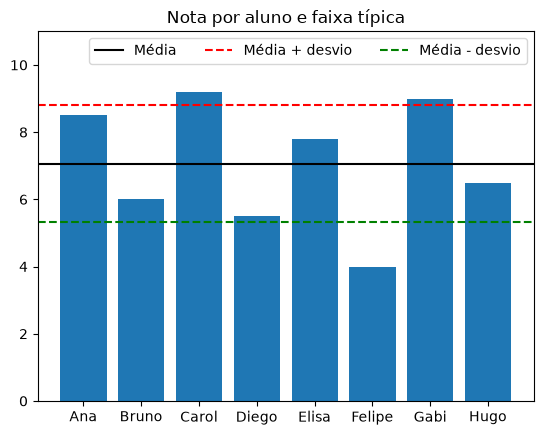

In [10]:
array_aluno = np.array(df_alunos['aluno'])
array_nota_aluno = np.array(df_alunos['nota'])

plt.bar(array_aluno, array_nota_aluno)
plt.axhline(media, color='black', label='Média')
plt.axhline(media + desvio, color='red', linestyle='--', label='Média + desvio')
plt.axhline(media - desvio, color='green', linestyle='--', label='Média - desvio')
plt.ylim(0, 11)
plt.legend(ncol=3)
plt.title('Nota por aluno e faixa típica')
plt.show()

**Leitura do gráfico:** as barras entre as duas linhas tracejadas estão dentro da faixa típica (5 alunos). **Felipe** (4,0) fica abaixo da faixa; **Carol** (9,2) e **Gabi** (9,0) ficam acima.

## 6.4 Desvio padrão vs margem de erro

*"Mas professor, isso não é igual à margem de erro que vejo nas pesquisas eleitorais?"* Quase, mas não é a mesma coisa.

| | Desvio padrão | Margem de erro |
|---|---|---|
| Fala sobre | Os **dados** em si | A **estimativa** |
| O que mede | O quanto os valores do conjunto variam entre si | A incerteza de uma pesquisa baseada em amostra |
| Exemplo | "As notas dos alunos têm desvio padrão de 1,74." | "Candidato tem 40% ± 2% de intenção de votos." |
| Significa | Os valores estão moderadamente espalhados em torno da média 7,06. | O valor real está entre 38% e 42% com certa confiança. |

**Resumo:** o desvio padrão descreve os dados. A margem de erro descreve a confiança na estimativa.

## 6.5 Covariância — duas variáveis juntas

*Será que notas e horas de estudo caminham juntas?*

**Analogia:** se dois amigos sempre chegam à escola juntos, eles têm uma relação positiva. A covariância faz isso com duas colunas: verifica se, quando uma sobe, a outra também sobe.

| Covariância | Significado | Exemplo |
|---|---|---|
| **Positiva** | Quando X sobe, Y também sobe. | Mais estudo → nota maior. |
| **Negativa** | Quando X sobe, Y desce. | Mais faltas → nota menor. |
| **Zero** | Nenhuma relação entre X e Y. | Altura e nota. |

### Covariância no Python

`np.cov()` **retorna uma matriz** com os valores:

In [ ]:
matriz_cov = np.cov(df_alunos['nota'], df_alunos['horas'])
print(matriz_cov)

Lendo a matriz 2×2 (linhas e colunas na ordem `nota`, `horas`):

| | nota | horas |
|---|---|---|
| **nota** | variância das notas | covariância |
| **horas** | covariância | variância das horas |

Na **diagonal** ficam as variâncias de cada variável; **fora da diagonal** fica a covariância entre as duas, igual nos dois lados.

> **Nota:** o `np.cov` faz um pequeno ajuste interno, por isso a variância na diagonal (3,46) fica um pouco diferente do `np.var` (3,02). O motivo fica para mais adiante.

Para extrair só o valor da covariância, pegamos a posição `[0, 1]` (linha 0, coluna 1):

In [ ]:
cov_valor = matriz_cov[0, 1]
print(f"Covariância: {cov_valor:.2f}")

Forma alternativa com Pandas: `.cov()` sobre as duas colunas devolve a mesma matriz, já com os nomes das variáveis.

In [ ]:
print(df_alunos[['nota', 'horas']].cov())

**Interpretação:** covariância = 4,48 > 0 → relação **positiva**. Mais horas de estudo tendem a dar nota maior. Mas qual é a **força** dessa relação? → Correlação!

## 6.6 Correlação — a força da relação

A covariância diz **se** existe relação. A correlação diz **o quanto** ela é forte.

**Problema da covariância:** o valor dela depende da escala dos dados. Se as notas fossem de 0 a 100, a covariância seria enorme, mas a relação seria a mesma! A correlação resolve isso: normaliza o valor para ficar sempre entre −1 e +1.

| r | Exemplo |
|---|---|
| r ≈ +1 | Mais horas de estudo → nota mais alta |
| r ≈ −1 | Mais faltas → nota mais baixa |
| r ≈ 0 | Altura do aluno → nota (sem relação) |

### Coeficiente de Pearson (r)

A forma mais comum de medir correlação **linear**. Em linguagem simples: o Pearson divide a covariância pelo produto dos desvios padrões das duas variáveis. Isso "normaliza" o resultado e garante que ele sempre fique entre −1 e +1.

| Valor de r | Leitura |
|---|---|
| 0,9 a 1,0 | Muito forte positiva |
| 0,7 a 0,9 | Forte positiva |
| 0,4 a 0,7 | Moderada positiva |
| −0,4 a +0,4 | Fraca / sem relação |
| −0,7 a −0,4 | Moderada negativa |
| −0,9 a −0,7 | Forte negativa |
| −1,0 a −0,9 | Muito forte negativa |

### Correlação no Python

Duas formas: `df.corr()` (Pandas, a mais usada na prática) e `np.corrcoef()` (NumPy, que também **retorna uma matriz**).

In [ ]:
# Forma 1 - Pandas
corr_pandas = df_alunos[['nota', 'horas']].corr()
print(corr_pandas)

# Forma 2 - NumPy
r = np.corrcoef(df_alunos['nota'], df_alunos['horas'])
print(r)
print(f"Pearson r = {r[0, 1]:.4f}")

**Interpretação:** r = 0,98 indica correlação **muito forte positiva**, quase perfeita entre horas de estudo e nota. Na matriz, a diagonal é sempre 1 (cada variável com ela mesma) e fora dela está a correlação entre as duas.

> **Relação linear:** o Pearson mede apenas correlação **linear**. Relações curvas exigem outros métodos. E correlação alta mostra que as variáveis andam juntas, mas não prova que uma **causa** a outra.

## 6.7 Vendo a relação: gráfico de dispersão e linha de tendência

O valor de r confirma o que o **gráfico de dispersão** (scatter) mostra. Cada aluno vira um ponto: horas de estudo no eixo x e nota no eixo y.

In [ ]:
array_horas_aluno = np.array(df_alunos['horas'])

plt.scatter(array_horas_aluno, array_nota_aluno)
plt.title('Horas de estudo (x) e nota (y) dos alunos')
plt.show()

Os pontos sobem da esquerda para a direita: relação positiva, como a covariância indicou. Para resumir essa relação em um traço, desenhamos a **linha de tendência**: a reta que melhor passa pelos pontos.

`np.polyfit(x, y, 1)` encontra a reta e devolve dois números: `a`, a **inclinação**, e `b`, o ponto onde a reta cruza o eixo y. A altura da reta para cada x é `a * x + b`.

In [ ]:
a, b = np.polyfit(array_horas_aluno, array_nota_aluno, 1)
linha = a * array_horas_aluno + b
print(round(a, 2), round(b, 2))

plt.scatter(array_horas_aluno, array_nota_aluno)
plt.plot(array_horas_aluno, linha, color='red')
plt.title('Horas de estudo (x) e nota (y) dos alunos')
plt.show()

**Como ler a reta junto com a correlação:**

| No gráfico | Nos números |
|---|---|
| Reta subindo | Covariância e correlação positivas |
| Reta descendo | Covariância e correlação negativas |
| Pontos colados na reta | Correlação perto de 1 ou de −1 |
| Pontos espalhados em volta da reta | Correlação perto de 0 |

Aqui a inclinação indica que cada hora a mais de estudo vem com cerca de 0,75 ponto a mais na nota, e os pontos ficam colados na reta, de acordo com r = 0,98.

O mesmo gráfico de dispersão, com a mesma linha de tendência e a mesma leitura, será refeito no **Power BI** nas aulas de visualização.

## 6.8 Código completo — tudo junto!

Do DataFrame ao relatório estatístico completo:

In [ ]:
import numpy as np
import pandas as pd

dados_alunos = {
    'aluno': ['Ana', 'Bruno', 'Carol', 'Diego', 'Elisa', 'Felipe', 'Gabi', 'Hugo'],
    'nota':  [8.5, 6.0, 9.2, 5.5, 7.8, 4.0, 9.0, 6.5],
    'horas': [6, 3, 8, 2, 5, 1, 7, 4]
}
df_alunos = pd.DataFrame(dados_alunos)

print(f"Variância:      {np.var(df_alunos['nota']):.2f}")
print(f"Desvio Padrão:  {np.std(df_alunos['nota']):.2f}")

cov = np.cov(df_alunos['nota'], df_alunos['horas'])[0, 1]
print(f"Covariância:    {cov:.2f}")

r = np.corrcoef(df_alunos['nota'], df_alunos['horas'])[0, 1]
print(f"Pearson r:      {r:.4f}")
print("Relação: MUITO FORTE POSITIVA!")

## 6.9 Resumão — os conceitos de hoje

| Conceito | Ideia | No Python |
|---|---|---|
| **Variância (σ²)** | Média das distâncias² em relação à média. Unidade = dados ao quadrado. | `np.var(array)` |
| **Desvio padrão (σ)** | Raiz da variância. Mesma unidade dos dados. O mais usado na prática! | `np.std(array)` |
| **Covariância** | Relação entre duas variáveis: > 0 positiva, < 0 negativa, ≈ 0 sem relação. | `np.cov(x, y)` |
| **Pearson (r)** | Força da correlação entre −1 e +1. Independe da escala dos dados. | `np.corrcoef(x, y)` |
| **Gráfico de dispersão e tendência** | Mostra a relação entre duas variáveis e a reta que a resume. | `plt.scatter()`, `np.polyfit()` + `plt.plot()` |

Lembre-se: todas as medidas usam **apenas variáveis quantitativas**.

---
## Atividades da Aula 6 — ocorrências de veículos no ISP-RJ

Nas atividades usamos a base do ISP-RJ. Siga o padrão de nomes: **`df_`** para DataFrames e **`array_<coluna>_<agrupamento>`** para arrays, como `array_roubo_veiculo_cisp`. As células abaixo leem a base com o nome `df_isp`.

In [ ]:
url = 'https://www.ispdados.rj.gov.br/Arquivos/BaseDPEvolucaoMensalCisp.csv'
df_isp = pd.read_csv(url, encoding='latin-1', sep=';')

### Atividade 6.1 — Faixa típica de roubo de veículos na Baixada

Base: `df_isp`, região `'Baixada Fluminense'`, ano **2024**, variável `roubo_veiculo`, uma linha por CISP.

1. Filtre a região e o ano em um `df_` e crie o array com o total de roubo de veículos por CISP.
2. Calcule a média, a variância e o desvio padrão.
3. Monte a faixa típica (média ± desvio padrão).
4. Descubra quantas CISPs ficaram dentro, acima e abaixo da faixa (use o mesmo filtro de DataFrame da Aula 4).
5. Desenhe o gráfico de barras com as linhas da média e da faixa típica.
6. O limite inferior da faixa fez sentido? O que isso diz sobre o espalhamento desses dados?

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

### Atividade 6.2 — Covariância na Baixada

Base: `df_isp`, `'Baixada Fluminense'`, **2024**, uma linha por CISP; variáveis `roubo_veiculo`, `furto_veiculos` e `recuperacao_veiculos`.

1. Prepare os três arrays no padrão: `array_roubo_veiculo_cisp`, `array_furto_veiculos_cisp` e `array_recuperacao_veiculos_cisp`.
2. Com `np.cov`, calcule a matriz de covariância de três pares: furto × roubo, roubo × recuperação e furto × recuperação, e pegue a covariância em `[0, 1]`.
3. Todos os sinais são positivos? O que isso significa em cada par?
4. Comparar os três valores diretamente é justo? Pense nas escalas dos dados.

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

### Atividade 6.3 — Correlação na Baixada

Use os mesmos três arrays da Atividade 6.2.

1. Com `np.corrcoef`, calcule a correlação dos três pares e imprima a matriz de cada um.
2. Classifique cada correlação com a tabela de Pearson: fraca, moderada, forte ou muito forte; positiva ou negativa.
3. Qual par tem a relação mais forte?
4. Compare com a covariância da Atividade 6.2: a ordem dos pares mudou? Por quê?

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

### Atividade 6.4 — O par mais correlacionado na Baixada

Base: `df_isp`, `'Baixada Fluminense'`, **2024**, uma linha por CISP.

1. Escolha o par de variáveis com a maior correlação na Atividade 6.3.
2. Monte o gráfico de dispersão desse par com a linha de tendência e um título descritivo.
3. Escreva 3 frases: o que a correlação indica, se o gráfico confirma e o que esse resultado não permite afirmar.
4. Para pensar: há pontos que fogem da reta? Que CISPs são esses?

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

In [ ]:
# Escreva seu código aqui

**Sua conclusão:** *(escreva aqui, em uma ou duas frases)*

---
## Resumo das ferramentas

| Ferramenta | Para que serve |
|---|---|
| `pd.read_excel()`, `pd.read_csv()` | Ler planilhas e arquivos CSV |
| `groupby().sum().reset_index()` + `sort_values(by=...)` | Agrupar, somar e ordenar |
| `np.array()`, `np.mean()`, `np.median()`, `np.percentile()` | Estatística em arrays |
| `(média - mediana) / mediana` | Avaliar se a média é confiável |
| IQR e limites (`Q3 + 1,5 × IQR`, `Q1 - 1,5 × IQR`) | Identificar outliers |
| `plt.bar()` / `plt.barh()` | Comparar categorias |
| `plt.plot()` | Mostrar a evolução no tempo |
| `plt.boxplot(orientation='horizontal', showmeans=True)` | Ver distribuição, média, mediana e outliers |
| `plt.text()` | Escrever valores e medidas no gráfico |
| `fig, axes = plt.subplots(linhas, colunas)` | Montar painéis |
| `np.var()`, `np.std()` | Variância e desvio padrão (espalhamento) |
| `média ± desvio padrão` | Faixa típica |
| `np.cov(x, y)[0, 1]` | Covariância (sentido da relação) |
| `np.corrcoef(x, y)[0, 1]`, `df.corr()` | Correlação de Pearson, de −1 a 1 |
| `plt.scatter()`, `np.polyfit()` + `plt.plot()` | Gráfico de dispersão e linha de tendência |